# 03 · Uni-Modal Contrast & Training Objective (paper §4.3–4.4, Eq. 11–12)

<div dir="rtl" style="text-align:right">

علاوه بر cross-modal، در **هر مودالیتی جداگانه** نود و context آن باید هم‌راستا باشند (Eq. 11):

- `gg`: $h^G_i \leftrightarrow \tilde h^G_i$ (گراف)
- `tt`: $h^T_i \leftrightarrow \tilde h^T_i$ (متن)

و هدف نهایی (Eq. 12): $\mathcal L=\mathcal L^{cross}+\gamma\,\mathcal L^{uni}$.


</div>

In [1]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")      # Windows: avoid the duplicate-OpenMP abort that kills the kernel
import faulthandler; faulthandler.enable()          # prints a native traceback to the Jupyter log if the kernel dies
import sys, json, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torch.nn.functional as F
from torch.utils.data import DataLoader
from cmucl_nb import common as C, views as V

cfg = C.load_config(); args = C.as_args(cfg); device = C.get_device(cfg)
C.set_cpu_threads()                          # leave some CPU cores free so the laptop stays responsive
C.fetch_official_code()                      # official repo -> ./third_party/CMUCL (not copied into this repo)
from model import CMUCL, tokenize            # official model + tokenizer
from data import DataHelper                  # official neighbour sampler

ds = C.load_saved_dataset()
x = torch.from_numpy(ds["feats"]).to(device)
edge_index = torch.from_numpy(ds["edge_index"]).to(device)
labels, texts = ds["labels"], ds["texts"]
print(f"dataset={cfg['dataset']}  device={device}  torch threads={torch.get_num_threads()}  nodes={ds['n']} (of {cfg.get('n_full')})  anomalies={labels.sum()}")

dataset=Citeseer  device=cpu  torch threads=4  nodes=384 (of 3186)  anomalies=19


In [2]:
model = CMUCL(args).to(device); C.prepare_model(model)   # CPU: thread limit + gradient checkpointing (same maths, far less RAM)
model.load_state_dict(torch.load(C.ART / "init_state.pt", map_location=device)); model.eval()
probe = V.load_probe(C.ART, texts, tokenize, args.context_length, device)
feats, logits = V.probe_logits(model, x, edge_index, probe, args.neigh_num)
scale = float(model.logit_scale.exp()); B = len(probe[0])
anom_pos = np.where(labels[probe[0].numpy()] == 1)[0]

C:\Users\KimiaMalekizadeh\AppData\Local\Temp\ipykernel_17020\3242446763.py:5: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  scale = float(model.logit_scale.exp()); B = len(probe[0])


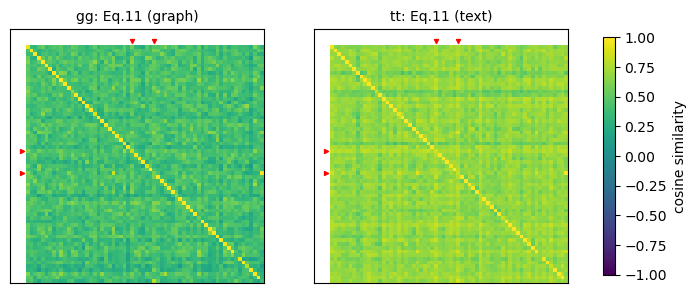

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4.4))
for a, k in zip(ax, V.UNI):
    im = V.plot_cos(a, logits[k], scale, f"{k}: {V.VIEW_INFO[k]['eq']}", anom_pos)
fig.colorbar(im, ax=ax, shrink=.7, label="cosine similarity"); C.savefig("03_uni_modal_matrices_init"); plt.show()

In [4]:
L = V.view_losses(logits); total, cross, uni = V.total_loss(L, args.gamma)
print(f"L_cross = {float(cross):.4f} | L_uni (Eq.11) = {float(uni):.4f} | gamma = {args.gamma} | L = L_cross + gamma*L_uni = {float(total):.4f}")

# ---- faithfulness check against the OFFICIAL forward (no optimiser step because training=False) ----
s_n, t_n, s_text, t_text = probe
with torch.no_grad():
    official = model.forward(x, edge_index, s_n, t_n, s_text, t_text, 0, device, training=False)
print(f"official model.forward loss = {official:.4f} | mine = {round(float(total), 4):.4f}")
assert abs(official - float(total)) < 2e-4, "mirror and official loss differ!"
print("OK: my decomposition reproduces the official loss")

L_cross = 17.9951 | L_uni (Eq.11) = 1.3742 | gamma = 0.005 | L = L_cross + gamma*L_uni = 18.0020
official model.forward loss = 18.0020 | mine = 18.0020
OK: my decomposition reproduces the official loss


<div dir="rtl" style="text-align:right">

## وزن هر view در loss و اثر $\gamma$

</div>

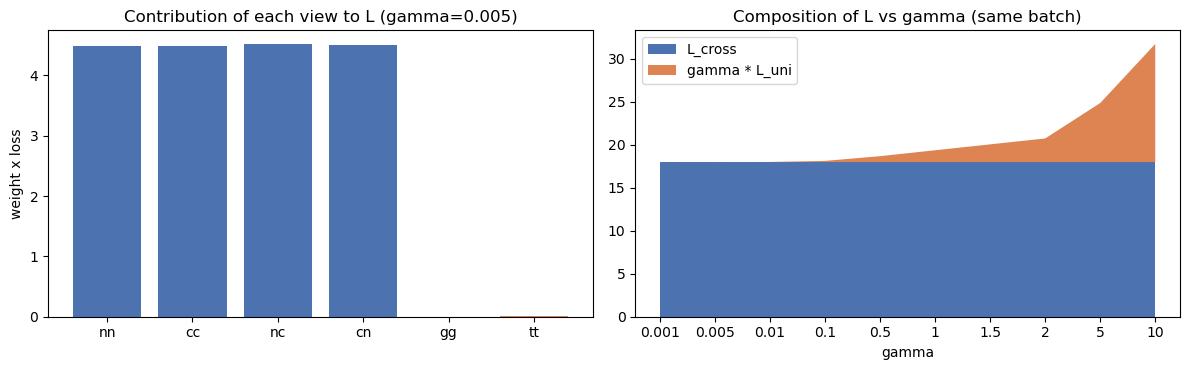

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
names = list(V.VIEW_INFO); w = [1, 1, 1, 1, args.gamma, args.gamma]
ax[0].bar(names, [float(L[k]) * wi for k, wi in zip(names, w)], color=["#4c72b0"] * 4 + ["#dd8452"] * 2)
ax[0].set_title(f"Contribution of each view to L (gamma={args.gamma})"); ax[0].set_ylabel("weight x loss")
gs = [0.001, 0.005, 0.01, 0.1, 0.5, 1, 1.5, 2, 5, 10]
ax[1].stackplot(range(len(gs)), [float(cross)] * len(gs), [g * float(uni) for g in gs], labels=["L_cross", "gamma * L_uni"], colors=["#4c72b0", "#dd8452"])
ax[1].set_xticks(range(len(gs))); ax[1].set_xticklabels(gs); ax[1].set_xlabel("gamma"); ax[1].legend(); ax[1].set_title("Composition of L vs gamma (same batch)")
plt.tight_layout(); C.savefig("03_loss_composition"); plt.show()
json.dump(dict(cross=float(cross), uni=float(uni), total=float(total), official=official, gamma=args.gamma), open(C.ART / "stage03.json", "w"), indent=1)